<h1 style='text-align: center'><b><i>This is the notebook where Analysis Begins</i><b></h1>

#### **Major question**

> **Did economic ouput and income per person increase, and what can we reasonably infer about changes in people's material living standards?**

#### **Terms to get fimiliar with it first**

```text
1. GDP per capita vs GNI per capita
2. Inflation and purchasing power.
3. Population growth and per-capita measures
4. Mean, median, distribution and inequality 
```
Explaination of these terms we'll be added in `Terms_explainations.md` file

**[Terms_explainations.md](Terms_explainations.md)**

### **Required modules**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

## **Subquestion 1**

> How did **GDP per capita** change?

#### **Parameters**

1. **How much did GDP per capita increase overall?**
    - Calculate absolute change and percentage change between the endpoints for each period.

2. **At what annual rate did GDP per capita grow?**
    - Calculate CAGR for each ten-year period and compare the results.

3. **Did GDP per capita grow consistently?**
    - Examine annual growth rates to identify slowdowns, accelerations, and contractions.

4. **Was the increase real or mainly due to prices**?
    - Compare current-price GDP per capita with constant-price GDP per capita.

### **Let's define an `Ingestion` function.**

In [3]:
def ingestion(file_path: str) -> pd.DataFrame:
    """opent the file and return the dataframe"""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f'[CRITICAL] {file_path} does not exists')
    else:
        try:
            df = pd.read_parquet(file_path)
            print(f'[SUCCESS] file loaded containing {len(df)} rows')
        except Exception as e:
            print(f'[CRITICAL] Failed to load {file_path}: {e}')

    
    return df

#### **Data Ingestion for Subquestion 1**

In [22]:
# file path for our dataset.
file_path: str = 'cleaned_datasets/Production/df_ver01_production.parquet'

subq1_df: pd.DataFrame = ingestion(file_path=file_path)

subq1_df.head(10)

[SUCCESS] file loaded containing 21 rows


,Year,GDPPC(current US$),GDPPC(current LCU),GDPPC(constant 2015 US$),GDPPC_growth(annual %),GDPPC(constant LCU)
0,2004,624.258827,28048.906064,892.596615,6.099965,77946.373254
1,2005,710.488080,31455.781950,947.732566,6.177029,82761.143276
2,2006,801.668354,36275.092169,1008.232753,6.383677,88044.347518
3,2007,1021.887077,41141.855321,1069.246968,6.051600,93372.439372
4,2008,992.519585,45649.565654,1086.506053,1.614135,94879.596145
5,2009,1094.949746,51948.412516,1155.101633,6.313410,100869.733922
6,2010,1347.519391,61395.941246,1235.159391,6.930798,107860.811225
7,2011,1445.461275,69268.600210,1281.610544,3.760742,111917.177550
8,2012,1429.321995,77768.134804,1333.096266,4.017267,116413.189792
9,2013,1432.843975,86689.811555,1399.453798,4.977700,122207.889108


### **Parameter 1: How much does GDP per capita increase overall**

- Calculate absolute change and percentage change between the endpoints for each period.

| | **Starts** | **Ends** |
|-|------------|----------|
| **Period 1** | 2004 | 2014 |
| **Period 2** | 2014 | 2024 |

In [23]:
# Let's find out GDPPC for these years.
years: list = [2004, 2014, 2024]

# GDPPC (current US$)
gdppc_current_us: dict = {}

# GDPPC (current LCU)
gdppc_current_lcu: dict = {}

# GDPPC (constant US$) 
gdppc_constant_us: dict = {}

# GDPPC (constant LCU)
gdppc_constant_lcu: dict = {}

for year in years:
    gdppc_cur_us = subq1_df[subq1_df['Year']==year]['GDPPC(current US$)'].item()
    gdppc_cur_lcu = subq1_df[subq1_df['Year']==year]['GDPPC(current LCU)'].item()
    gdppc_cons_us = subq1_df[subq1_df['Year']==year]['GDPPC(constant 2015 US$)'].item()
    gdppc_cons_lcu = subq1_df[subq1_df['Year']==year]['GDPPC(constant LCU)'].item()

    # let's assign them inside their dictionaries.
    gdppc_current_us[year] = gdppc_cur_us
    gdppc_current_lcu[year] = gdppc_cur_lcu
    gdppc_constant_us[year] = gdppc_cons_us
    gdppc_constant_lcu[year] = gdppc_cons_lcu

In [24]:
# Periods 
periods: list = [
    [2004, 2014],
    [2014, 2024]
]

per_no = 1

# calculated data
calculated_data: dict = {}
for period in periods:
    # Absolute increase in GDPPC (current US$) 
    abs_inc_cur_us = gdppc_current_us[period[1]] - gdppc_current_us[period[0]]
    # Absolute increase in GDPPC (current LCU)
    abs_inc_cur_lcu = gdppc_current_lcu[period[1]] - gdppc_current_lcu[period[0]]
    # Absolute increase in GDPPC (constant 2015 US$)
    abs_inc_cons_us = gdppc_constant_us[period[1]] - gdppc_constant_us[period[0]]
    # Absolute increase in GDPPC (constant LCU)
    abs_inc_cons_lcu = gdppc_constant_lcu[period[1]] - gdppc_constant_lcu[period[0]]


    # Percentage increase in GDPPC (current US$)
    per_inc_cur_us = ((gdppc_current_us[period[1]] - gdppc_current_us[period[0]]) /  gdppc_current_us[period[0]]) * 100 
    # Percentage increase in GDPPC (current LCU)
    per_inc_cur_lcu = ((gdppc_current_lcu[period[1]] - gdppc_current_lcu[period[0]]) /  gdppc_current_lcu[period[0]]) * 100 
    # Percentage increase in GDPPC (constant 2015 US$)
    per_inc_cons_us = ((gdppc_constant_us[period[1]] - gdppc_constant_us[period[0]]) /  gdppc_constant_us[period[0]]) * 100 
    # Percentage increase in GDPPC (constant LCU)
    per_inc_cons_lcu = ((gdppc_constant_lcu[period[1]] - gdppc_constant_lcu[period[0]]) /  gdppc_constant_lcu[period[0]]) * 100 

    # Assigning that datapoint to calculated data dictionary
    calculated_data[f'Period {per_no}'] = {
        'abs_inc_current_US$' : abs_inc_cur_us,
        'abs_inc_current_LCU(₹)': abs_inc_cur_lcu,
        'abs_inc_constant_2015_US$' : abs_inc_cons_us,
        'abs_inc_constant_LCU(₹)': abs_inc_cons_lcu,
        '%_inc_current_US$' : per_inc_cur_us,
        '%_inc_current_LCU(₹)' : per_inc_cur_lcu,
        '%_inc_constant_2015_US$' : per_inc_cons_us,
        '%_inc_constant_LCU(₹)': per_inc_cons_lcu
    }

    per_no = 2

# Let's convert the findings into a new dataframe.
gddppc_df = pd.DataFrame(calculated_data)

# we have calculated these figures from unrounded value but it would be better
# if we round the result.
gddppc_df['Period 1'] = gddppc_df['Period 1'].round(2)
gddppc_df['Period 2'] = gddppc_df['Period 2'].round(2)

gddppc_df

,Period 1,Period 2
abs_inc_current_US$,929.63,1038.11
abs_inc_current_LCU(₹),66961.20,124209.17
abs_inc_constant_2015_US$,591.72,882.52
abs_inc_constant_LCU(₹),51672.18,77066.12
%_inc_current_US$,148.92,66.81
%_inc_current_LCU(₹),238.73,130.73
%_inc_constant_2015_US$,66.29,59.46
%_inc_constant_LCU(₹),66.29,59.46


In [25]:
gddppc_df = gddppc_df.T

gddppc_df = gddppc_df.reset_index()

In [26]:
# renaming the index columns.
gddppc_df = gddppc_df.rename(columns={'index': 'periods'})

gddppc_df

,periods,abs_inc_current_US$,abs_inc_current_LCU(₹),abs_inc_constant_2015_US$,abs_inc_constant_LCU(₹),%_inc_current_US$,%_inc_current_LCU(₹),%_inc_constant_2015_US$,%_inc_constant_LCU(₹)
0,Period 1,929.63,66961.20,591.72,51672.18,148.92,238.73,66.29,66.29
1,Period 2,1038.11,124209.17,882.52,77066.12,66.81,130.73,59.46,59.46


### **Parameter 2 - At what annual rate did GDP per capita grow?**

- Calculate **CAGR** for each ten-year period and compare the results.

The formula:
> **(((Ending value / Beginning value) ^ 1/n) - 1) * 100**

In [27]:
# CAGR of GDP per capita (constant 2015 US$)
cagr_period_1 = (((gdppc_constant_us[2014] / gdppc_constant_us[2004]) ** (1 / 10)) - 1) * 100
cagr_period_2 = (((gdppc_constant_us[2024] / gdppc_constant_us[2014]) ** (1 / 10)) - 1) * 100

print(f'CAGR of GDP per capita (constant 2015 US$):\nPeriod 1 -> {cagr_period_1:.2f}%\nPeriod 2 -> {cagr_period_2:.2f}%')

CAGR of GDP per capita (constant 2015 US$):
Period 1 -> 5.22%
Period 2 -> 4.78%


### **Parameter 3 - Did GDP per capita grow consistently?**

- Examining annual growth rates to identify slowdowns, accelerations, and contractions.

**Via visualizing with help of a line plot**

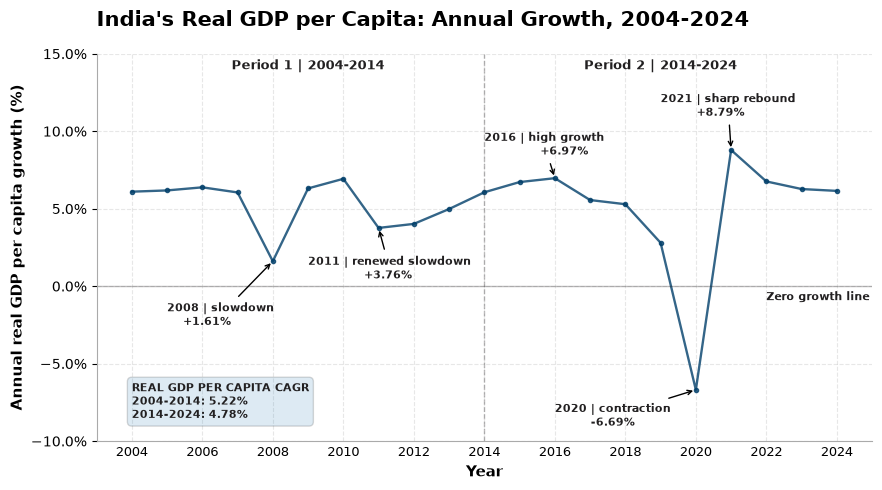

In [13]:
from matplotlib.ticker import PercentFormatter # percentage labels

# years would be on x axis
x_axis = subq1_df['Year']
# GDPPC annual growth (%) rounded value, would be on y axis
y_axis = subq1_df['GDPPC_growth(annual %)'].round(2)

# initiating figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Plotting
ax.plot(
    x_axis,
    y_axis,
    marker='o',
    markersize= 3,
    linewidth=1.7,
    color='#013F6A',
    alpha=0.8
)

# titles and labels
ax.set_title("India's Real GDP per Capita: Annual Growth, 2004-2024", fontsize=15, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Annual real GDP per capita growth (%)', fontsize=11, fontweight='bold')

# ticks and tick labels.
ax.set_ylim(-10, 15)
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.set_xticks([2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])

# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# grids
ax.grid(axis='both', alpha=0.3, linestyle='--')

# vertical line on 2014 refrence the transition year.
ax.axvline(
    2014,
    linestyle='--',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# Horizontal line on 0.0% refrence the zero growth line.
ax.axhline(
    0.0,
    linestyle='-',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# text for zero growth
ax.text(
    2022,
    -0.9,
    'Zero growth line',
    fontsize=8,
    fontweight='bold',
    color='#222021'
)

# period text
ax.text(
    2009,
    14,
    f'Period 1 | 2004-2014',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center'
)
ax.text(
    2019,
    14,
    f'Period 2 | 2014-2024',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center'
)

# Annotations
ax.annotate(
    f'REAL GDP PER CAPITA CAGR\n2004-2014: {cagr_period_1:.2f}%\n2014-2024: {cagr_period_2:.2f}%',
    xy=(2004, -5.0),
    xytext=(2004, -8.5),
    fontsize=8,
    fontweight='bold',
    color= '#222021',
    bbox=dict(boxstyle='round,pad=0.4', alpha=0.15),
)

ax.annotate(
    f'2008 | slowdown\n    +{subq1_df[subq1_df['Year']==2008]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2008, subq1_df[subq1_df['Year']==2008]['GDPPC_growth(annual %)'].item()),
    xytext=(2005, -2.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2011 | renewed slowdown\n{' '*14}+{subq1_df[subq1_df['Year']==2011]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2011, subq1_df[subq1_df['Year']==2011]['GDPPC_growth(annual %)'].item()),
    xytext=(2009, 0.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)

ax.annotate(
    f'2016 | high growth\n{' '*14}+{subq1_df[subq1_df['Year']==2016]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2016, subq1_df[subq1_df['Year']==2016]['GDPPC_growth(annual %)'].item()),
    xytext=(2014, 8.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2020 | contraction\n{' '*9}{subq1_df[subq1_df['Year']==2020]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2020, subq1_df[subq1_df['Year']==2020]['GDPPC_growth(annual %)'].item()),
    xytext=(2016, -9.),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2021 | sharp rebound\n{' '*9}+{subq1_df[subq1_df['Year']==2021]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2021, subq1_df[subq1_df['Year']==2021]['GDPPC_growth(annual %)'].item()),
    xytext=(2019, 11),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)


plt.tight_layout()
plt.show()


### **Parameter 4 - Was the increase real or mainly due to prices**?
- Comparing current-price GDP per capita with constant-price GDP per capita.

Again **visualizing with the help of a line plot**

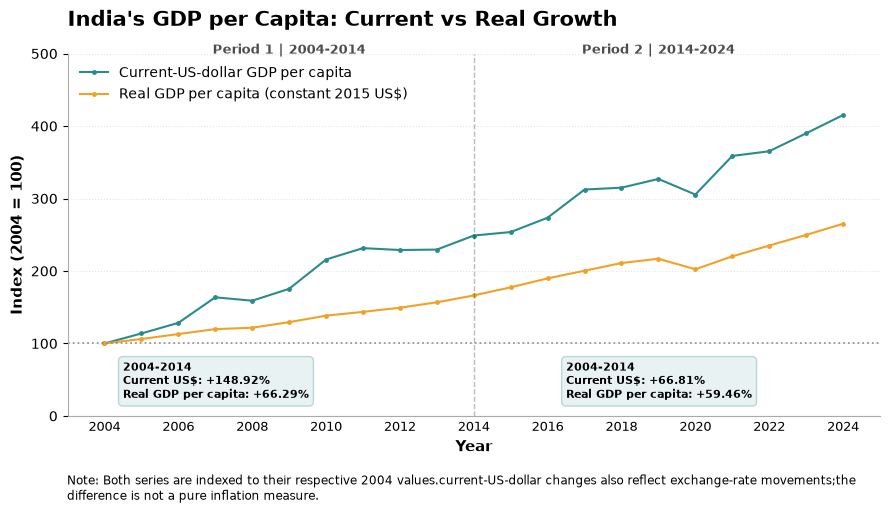

In [28]:
nominal_gddppc = list(((subq1_df['GDPPC(current US$)'] / subq1_df[subq1_df['Year'] == 2004]['GDPPC(current US$)'].item()) * 100).round(2))
real_gddpc = list(((subq1_df['GDPPC(constant 2015 US$)'] / subq1_df[subq1_df['Year'] == 2004]['GDPPC(constant 2015 US$)'].item()) * 100).round(2))
year = subq1_df['Year']
# Initiating figure and axes.
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    year,
    nominal_gddppc,
    marker='o',
    markersize=2.5,
    linewidth=1.5,
    label='Current-US-dollar GDP per capita',
    color='#298c8c'
)

ax.plot(
    year,
    real_gddpc,
    marker='o',
    markersize=2.5,
    linewidth=1.5,
    label='Real GDP per capita (constant 2015 US$)',
    color='#f1a226'
)

# titles and labels
ax.set_title("India's GDP per Capita: Current vs Real Growth", fontsize=15, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Index (2004 = 100)', fontsize=11, fontweight='bold')

# ticks and ticklabels
ax.set_ylim(0, 500)
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.set_xticks(range(2004, 2025, 2))
# grid
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.grid(axis='x', visible=False)
# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# vertical line on 2014 represent Transitional year.
ax.axvline(
    2014,
    linestyle='--',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# Baseline: each series equals 100 in 2004.
ax.axhline(
    y=100,
    color="gray",
    linestyle=":",
    linewidth=1.3,
    alpha=0.8
)

current_p1 = gddppc_df[gddppc_df['periods']=='Period 1']['%_inc_current_US$'].item()
current_p2 = gddppc_df[gddppc_df['periods']=='Period 2']['%_inc_current_US$'].item()
real_p1 = gddppc_df[gddppc_df['periods']=='Period 1']['%_inc_constant_2015_US$'].item()
real_p2 = gddppc_df[gddppc_df['periods']=='Period 2']['%_inc_constant_2015_US$'].item()
# PERIOD SUMMARY BOXES
ax.text(
    2004.5,
    25,
    f'2004-2014\n'
    f'Current US$: +{current_p1:.2f}%\n'
    f'Real GDP per capita: +{real_p1:.2f}%',
    fontsize=8,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='#E8F2F3',
        edgecolor='#B8D4D5',
        alpha=0.95
    )
)
ax.text(
    2016.5,
    25,
    f'2004-2014\n'
    f'Current US$: +{current_p2:.2f}%\n'
    f'Real GDP per capita: +{real_p2:.2f}%',
    fontsize=8,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='#E8F2F3',
        edgecolor='#B8D4D5',
        alpha=0.95
    )
)

ax.text(
    2009,
    500,
    'Period 1 | 2004-2014',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center',
    alpha=0.8
)
ax.text(
    2019,
    500,
    'Period 2 | 2014-2024',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center',
    alpha=0.8
)

# Footer
fig.text(
    0.08,
    -0.01,
    "Note: Both series are indexed to their respective 2004 values."
    "current-US-dollar changes also reflect exchange-rate movements;"
    "the\ndifference is not a pure inflation measure.",
    fontsize=8.5
    
)

ax.legend(frameon=False, loc='upper left')
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### **Conclusion — How Did India's GDP per Capita Change?**

```text
India's GDP per capita increased sustantially between 2004 and 2024, although the pace and magnitude of growth differed between the two study periods.

During **Period 1 (2004-2014)**, real GDP per capita, measured in constant 2015 US dollars, increased from $892.60 to $1,484.32. This represented an absolute increase of $591.72, or 66.29%, with a compound annual growth rate (CAGR) of 4.22%.

During **Period 2 (2014-2024)**, real GDP per capita increased from $1,484.32 to $2,366.83, an absolute increase of $882.51, or 59.46%. Its CAGR declined to 4.78%. Thus, the second period recorded a larger absolute increase in real GDP per capita, but the first period experienced faster percentage growth and a higher annaulized growth rate.

The annual growth trajectory shows that this increase was not uniform. Growth experienced notable slowdowns in 2008 and 2011, strengthened overt the following years, and then weakened before the contraction in 2020. A sharp rebound followed in 2021, after which growth moderated through 2024. These fluctuations why endpoint comparisons alone do not fully describe changes in GDP per capita.

A comparison of current-price and constant-price measures further shows that nominal GDP per capita increased much faster than real GDP per capita, particularly during 2004-2014. Current-US-dollar GDP per capita increased by 148.92% in the first period and 66.81% in the second, compared with real increases of 66.29% and 59.46%, respectively. Current-LCU increases were larger still, indicating that domestic price changes were an important consideration when interpreting nominal values. However, current-US-dollar changes also reflect exchange-rate movements, so their difference from real growth cannont be attributed entirely to inflation.

Overall, India's real GDP per capita increased substantially in both periods, indicating higher average real economic output per person. Nevertheless, the pace of this increase slowed during 2014-2024. These findings also highlight the importance of distinguishing GDP per capita from personal income or household living standards: GDP per capita is an average measure of economic output and does not show how that output is distributed across the population.
```

## **Suquestion 2**

> **How did GNI per capita change?**

#### **Parameters**

1. **How much did GNI per capita increase overall?**

    - Calculate the absolute change and percentage change for each period.

    - **What it answers:** How much did national income per person change over each decade?

2. **At what annual rate did GNI per capita grow?**

    - Calculate the CAGR of **real GNI per capita** for both ten-year periods.

    - **What it answers:** Was the long-term pace of national income growth per peron faster in 2004-2014 or 2014-2024?

3. **Did GNI per capita grow consistently?**

    - Examine the annual real GNI-per-capita growth rates to identify slowdowns, accelerations and contractions. (mean growth rate, standard deviation, maximum, minimum, number of weak-growth years, and number of negative-growth years).

    - **What it answers:** Did national income per person grow steadily, or did its growth fluctuate substiantially?

4. **Did national income per person follow the same pattern as domestic output per person?**
    
    - Compare: Real GDP per capita vs Real GNI per capita.

    - **What it answers:** Did real national income per person grow faster or slower than real domestic output per person?

5. **Was the increase real or mainly due to prices?**

    - Compare the current-value and constant-price measures of GNI per capita.

    - **what it answers:** How different was the increase in current-dollar GNI per capita from the increase in real GNI per capita?

6. **Did net primary income from abroad change the relationship between GDP and GNI?**

    - It investigates _Why_ real GNI per capita migh follow a different pattern from real GDP per capita.<br><br> **GNI = GDP + Net primary income from abroad**

    - **What it answers:** Did India's net primary income received from abraod become more positive, less positive, or more negative relative to domestic production?

### **Data Ingestion for subquestion 2**

We already have the ingestion function...we will use it.

In [128]:
# file_path:
file_path2: str = 'cleaned_datasets/Production/GNI_df_production.parquet'

subq2_df: pd.DataFrame = ingestion(file_path=file_path2)

subq2_df.head()

[SUCCESS] file loaded containing 21 rows


,Year,GNI_Atlas(current US$),GNI(current US$),GNI(current LCU),GNI(constant 2015 US$),GNI_growth(annual %),GNI(constant LCU),GNIPC_Atlas(current US$),GNIPC(constant 2015 US$),GNIPC_growth(annual %),GNIPC(constant LCU)
0,2004,6.872846e+11,7.041729e+11,3.163957e+13,1.001830e+12,6.449812,8.816203e+13,610.0,886.736349,6.098579,77396.094204
1,2005,8.090880e+11,8.144850e+11,3.606009e+13,1.085237e+12,8.325456,9.550192e+13,700.0,941.306791,6.154077,82159.109818
2,2006,9.169864e+11,9.329153e+11,4.221395e+13,1.175269e+12,8.296087,1.034248e+14,780.0,1000.773703,6.317485,87349.498913
3,2007,1.081968e+12,1.211642e+12,4.878150e+13,1.269047e+12,7.979199,1.116773e+14,910.0,1065.140282,6.431682,92967.540688
4,2008,1.195031e+12,1.191737e+12,5.481229e+13,1.325168e+12,4.422349,1.166161e+14,990.0,1080.483506,1.440489,94306.727496


**Data ingestion successful**

### **Parameter 1 — How much did GNI per capita increase overall**

- Calculating the absolute change and percentage change for each period.

- **What it answers:** How much did national income per person change over each decade?


In [5]:
# we'll measure those for both GNI (current US$) and GNI (constant 2015 US$)

# But first let's get hold with the values of following years
years: list = [2004, 2014, 2024]

gnipc_current: dict = {}
gnipc_constant: dict = {}

for year in years:
    current: float = subq2_df.loc[subq2_df['Year']==year, 'GNIPC_Atlas(current US$)'].round(2).item()
    constant: float = subq2_df.loc[subq2_df['Year']==year, 'GNIPC(constant 2015 US$)'].round(2).item()

    # allocating them inside their respected dictionary
    gnipc_current[year] = current
    gnipc_constant[year] = constant

print(f'GNI PC current US$: {gnipc_current}\nGNI PC constant 2015 US$: {gnipc_constant}')

GNI PC current US$: {2004: 610.0, 2014: 1540.0, 2024: 2550.0}
GNI PC constant 2015 US$: {2004: 886.74, 2014: 1467.13, 2024: 2334.91}


**Absolute change**

Formula:
> **Ending years value - beginning years value**

e.g. (Abs change in Period 1 = GNI PC 2014 - GNI PC 2004)

In [6]:
# Let's collect the absolute change in GNI per capita for each period.
periods: list = [
    [2004, 2014],
    [2014, 2024]
]

absolute_change: dict = {}
per_no = 1
for period in periods:
    current_inc: float = round(gnipc_current[period[1]] - gnipc_current[period[0]],2)
    constant_inc: float = round(gnipc_constant[period[1]] - gnipc_constant[period[0]],2)

    # assigning to the absolute_increase dictionary.
    absolute_change[f'Period {per_no}'] = {
        'current': current_inc,
        'constant': constant_inc
    }
    per_no += 1

print('Absolute Change in GNI per capita in both period:')
absolute_change

Absolute Change in GNI per capita in both period:


{'Period 1': {'current': 930.0, 'constant': 580.39},
 'Period 2': {'current': 1010.0, 'constant': 867.78}}

**Change in percentage**

Formula:
> **((Ending year's value - Beginning year's value) / Beginning year's value) x 100**

e.g. ((GNI PC 2014 - GNI PC 2004) / GNI PC 2004) x 100

In [7]:
# Now we're gonna calculate the percentage change in GNI per capita for each period.
percentage_change: dict = {}
per_no = 1
for period in periods:
    current_change_per: float = round(((gnipc_current[period[1]] - gnipc_current[period[0]]) / gnipc_current[period[0]]) * 100, 2)
    constant_change_per: float = round(((gnipc_constant[period[1]] - gnipc_constant[period[0]]) / gnipc_constant[period[0]]) * 100, 2)

    # assinging to the dictionary
    percentage_change[f'Period {per_no}'] = {
        'change_%_current': current_change_per,
        'change_%_constant': constant_change_per
    }
    per_no +=1

print('Percentage change in GNI per capita for both Periods:')
percentage_change

Percentage change in GNI per capita for both Periods:


{'Period 1': {'change_%_current': 152.46, 'change_%_constant': 65.45},
 'Period 2': {'change_%_current': 65.58, 'change_%_constant': 59.15}}

### **Parameter 2 — At what annual rate did GNI per capita grow?**

- Calculating the CAGR of **real GNI per capita** for both ten-year periods.

- **What it answers:** Was the long-term pace of national income growth per peron faster in 2004-2014 or 2014-2024?

Formula for CAGR (%):

> **(((Ending year's value / Biginning year's) ^ (1/n)) - 1) x 100** Where _n_ = number of years between each periods for this case 10.

In [8]:
# Calculating the CAGR (%) of real GNI per capita for each period.

cagr_percentage_gnipc: dict = {}
per_no = 1
for period in periods:
    cagr_percentage_constant: float = round(
        (((gnipc_constant[period[1]]/gnipc_constant[period[0]]) ** (1/10)) - 1) * 100, 2
    )
    # assigning to the dictionary.
    cagr_percentage_gnipc[f'Period {per_no}'] = cagr_percentage_constant
    per_no += 1

print('CAGR (%) of real GNI per capita for both period:')
cagr_percentage_gnipc

CAGR (%) of real GNI per capita for both period:


{'Period 1': 5.16, 'Period 2': 4.76}

### **Parameter — 3 Did GNI per capita grow consistently?**

- Examine the annual real GNI-per-capita growth rates to identify slowdowns, accelerations and contractions. (mean growth rate, standard deviation, maximum, minimum, number of weak-growth years, and number of negative-growth years).

- **What it answers:** Did national income per person grow steadily, or did its growth fluctuate substiantially?

In [9]:
gnipc_growth_period_1 = (subq2_df['Year'] >= 2004) & (subq2_df['Year'] <= 2014)
gnipc_growth_period_2 = (subq2_df['Year'] >= 2014) & (subq2_df['Year'] <= 2024)

df_periods: list = [gnipc_growth_period_1, gnipc_growth_period_2]

growth_consistency_gnipc: dict = {}
per_no = 1
for period in df_periods:
    mean_gni_growth: float = round(float(subq2_df.loc[period, 'GNIPC_growth(annual %)'].mean()),2)
    # Using ddof = 0 since we posses every observation for the population
    std_gni_growth: float = round(float(subq2_df.loc[period, 'GNIPC_growth(annual %)'].std(ddof=0)),2)
    # Maximum growth rate.
    max_gni_growth: float = round(float(subq2_df.loc[period, 'GNIPC_growth(annual %)'].max()),2)
    # Minimum growth rate.
    min_gni_growth: float = round(float(subq2_df.loc[period, 'GNIPC_growth(annual %)'].min()), 2)

    # assigning it to the dictionary.
    growth_consistency_gnipc[f'Period {per_no}'] = {
        'mean': mean_gni_growth,
        'Standard deviation': std_gni_growth,
        'maximum growth': max_gni_growth,
        'Minimum growth': min_gni_growth
    }
    per_no +=1

pd.DataFrame(growth_consistency_gnipc)

,Period 1,Period 2
mean,5.26,4.96
Standard deviation,1.54,4.07
maximum growth,6.43,8.99
Minimum growth,1.44,-7.15


In [59]:
# let's give a standard limit for weak growth on dimension 1 We used 4% 
# That means if the growth falls below 4% it would be a weak year. And below
# 0% negative growth years.

# So let's calculate weak growth for each period.
weak_mask_period_1 = ((subq2_df['Year'] >=2004) & (subq2_df['Year'] <=2014)) & (subq2_df['GNIPC_growth(annual %)'] < 4.0)
weak_mask_period_2 = ((subq2_df['Year'] >=2014) & (subq2_df['Year'] <=2024)) & (subq2_df['GNIPC_growth(annual %)'] < 4.0)

weak_year_period_1 = subq2_df.loc[weak_mask_period_1, ['Year', 'GNIPC_growth(annual %)']]
weak_year_period_2 = subq2_df.loc[weak_mask_period_2, ['Year', 'GNIPC_growth(annual %)']]

print(
    'Number of weak growth year:\n'
    f'Period 1 -> {len(weak_year_period_1)}\n'
    f'Period 2 -> {len(weak_year_period_2)}')

# Now negative growth rate for each period (growth rate < 0.0)
negative_mask_period_1 = ((subq2_df['Year'] >=2004) & (subq2_df['Year'] <=2014)) & (subq2_df['GNIPC_growth(annual %)'] < 0.0)
negative_mask_period_2 = ((subq2_df['Year'] >=2014) & (subq2_df['Year'] <=2024)) & (subq2_df['GNIPC_growth(annual %)'] < 0.0)

negative_year_period_1 = subq2_df.loc[negative_mask_period_1, ['Year', 'GNIPC_growth(annual %)']]
negative_year_period_2 = subq2_df.loc[negative_mask_period_2, ['Year', 'GNIPC_growth(annual %)']]
print(
    'Number of negative growth year (Contraction):\n'
    f'Period 1 -> {len(negative_year_period_1)}\n'
    f'Period 2 -> {len(negative_year_period_2)}'
    )

Number of weak growth year:
Period 1 -> 3
Period 2 -> 2
Number of negative growth year (Contraction):
Period 1 -> 0
Period 2 -> 1


### **let's visualize the growth of real GNI per capita growth**

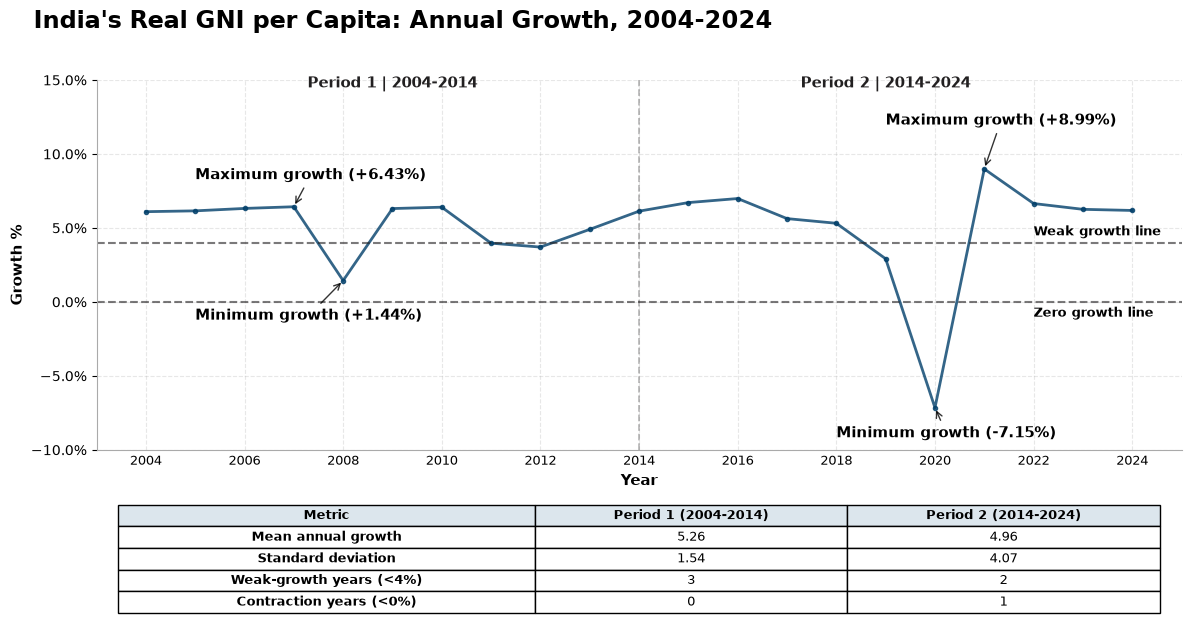

In [127]:
from matplotlib.ticker import PercentFormatter

# Initiating fig and axes.
fig = plt.figure(figsize=(14, 7))

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[4, 1.3],
    hspace=0.2
)

# Top area: line chart
ax = fig.add_subplot(gs[0])

# Bottom area: summary table
ax_table = fig.add_subplot(gs[1])

# ploting
ax.plot(
    subq2_df['Year'],
    subq2_df['GNIPC_growth(annual %)'],
    linewidth=2.0,
    marker='o',
    markersize=3.0,
    color='#013F6A',
    alpha=0.8
)

# Titles and layouts
# ax.set_title('GNI per capita annual growth % (2004 - 2024)', fontsize=14, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Growth %', fontsize=11, fontweight='bold')

# ticks and their labels
ax.set_ylim(-10, 15)
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.set_xticks([2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])

# grid
ax.grid(axis='both', linestyle='--', alpha=0.3)

# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# vertical line for transition year (2004)
ax.axvline(
    2014,
    linestyle='--',
    linewidth=1.3,
    alpha=0.3,
    color='#222021'
)

# horizontal line (zero growth line y=0)
ax.axhline(
    0.0,
    linestyle='--',
    linewidth=1.5,
    alpha=0.6,
    color='#222021'
)

# horizontal line(weak growht line y < 4.0)
ax.axhline(
    4.0,
    linestyle='--',
    linewidth=1.5,
    alpha=0.6,
    color='#222021'
)

# text
ax.text(
    2022,
    4.5,
    'Weak growth line',
    fontsize=9,
    fontweight='bold'
)

ax.text(
    2022,
    -1.0,
    'Zero growth line',
    fontsize=9,
    fontweight='bold'
)

ax.text(
    2009,
    14.5,
    'Period 1 | 2004-2014',
    fontsize=11,
    fontweight='bold',
    ha='center',
    color='#222021'
)
ax.text(
    2019,
    14.5,
    'Period 2 | 2014-2024',
    fontsize=11,
    fontweight='bold',
    ha='center',
    color='#222021'
)

# Annotations
ax.annotate(
    f'Maximum growth (+{growth_consistency_gnipc['Period 1']['maximum growth']}%)',
    xy=(2007, 6.43),
    xytext=(2005, 8.3),
    fontsize=11,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='->',
        alpha=0.8
    )
)

ax.annotate(
    f'Minimum growth (+{growth_consistency_gnipc['Period 1']['Minimum growth']}%)',
    xy=(2008, 1.44),
    xytext=(2005, -1.2),
    fontsize=11,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='->',
        alpha=0.8
    )
)

ax.annotate(
    f'Maximum growth (+{growth_consistency_gnipc['Period 2']['maximum growth']}%)',
    xy=(2021, 8.99),
    xytext=(2019, 11.99),
    fontsize=11,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='->',
        alpha=0.8
    )
)
ax.annotate(
    f'Minimum growth ({growth_consistency_gnipc['Period 2']['Minimum growth']}%)',
    xy=(2020, -7.15),
    xytext=(2018, -9.15),
    fontsize=11,
    fontweight='bold',
    arrowprops=dict(
        arrowstyle='->',
        alpha=0.8
    )
)

#-----------------------------------------------------------------------
# SUMMARY TABLE
#----------------------------------------------------------------------

table_rows = [
    [
        "Mean annual growth",
        f"{growth_consistency_gnipc['Period 1']['mean']}",
        f'{growth_consistency_gnipc['Period 2']['mean']}'
    ],
    [
        "Standard deviation",
        f"{growth_consistency_gnipc['Period 1']['Standard deviation']}",
        f"{growth_consistency_gnipc['Period 2']['Standard deviation']}"
    ],
    [
        "Weak-growth years (<4%)",
        str(len(weak_year_period_1)),
        str(len(weak_year_period_2))
    ],
    [
        "Contraction years (<0%)",
        str(len(negative_year_period_1)),
        str(len(negative_year_period_2))
    ]
]

# Hide the table area's axes
ax_table.axis("off")

# Create the table
summary_table = ax_table.table(
    cellText=table_rows,
    colLabels=[
        "Metric",
        "Period 1 (2004-2014)",
        "Period 2 (2014-2024)"
    ],
    cellLoc="center",
    colLoc="center",
    colWidths=[0.40, 0.30, 0.30],
    bbox=[0.02, 0.05, 0.96, 0.90]
)

# TABLE FORMATTING
summary_table.auto_set_font_size(False)
summary_table.set_fontsize(9.5)
summary_table.scale(1, 1.4)

# Style the header
for col in range(3):
    cell = summary_table[(0, col)]
    cell.set_text_props(weight='bold')
    cell.set_facecolor('#DCE6ED')

# Highlight metric names
for row in range(1, len(table_rows) + 1):
    summary_table[(row, 0)].set_text_props(weight='bold')

# Finally adjust the layout
fig.suptitle(
    "India's Real GNI per Capita: Annual Growth, 2004-2024",
    fontsize=17,
    fontweight='bold',
    x=0.08,
    ha='left'
)
# plt.tight_layout()
plt.show()

### **Conclusion — for the Chart**

```text
Period 1 (2004-2014): Real GNI per capita grew at an average annual rate of 5.26%, with relatively low volatility (1.54 percentage points). Despite the sharp slowdown in 2008 and further weakening around 2011-2012, growth recovered and strenghtened through 2016 in the wider trajectory.

Period 2 (2014-2024): Average growth moderated slightly to 4.96%, but volatility increased substantially. The most significant event was the 2020 contraction of -7.15%, followed by a sharp rebound to 8.99% in 2021 and more moderate growth thereafter.

The striking finding is that the average growth rates were quite close, but the consistency of growth differed considerably between the periods.
```
